# Rotated Surface-Code Memory Simulation

This notebook simulates logical $X$- and $Z$-memory experiments using Stim's generated rotated surface-code circuits.

### Workflow

1. Generate noisy logical $X$- and $Z$-memory circuits.
2. Inspect qubit, detector, and measurement counts.
3. Visualise the surface-code layout and circuit timeline.
4. Construct detector error models (DEMs).
5. Decode sampled detection events with PyMatching.
6. Estimate logical failure probabilities.
7. Compare logical $X$- and $Z$-memory behaviour.
8. Benchmark batch-decoding throughput and single-shot latency.

### Background

The rotated surface code protects a single logical qubit using a two-dimensional lattice of data and ancilla (measurement) qubits. Repeated stabilizer measurements generate detection events, framing error correction as a space-time minimum-weight perfect matching (MWPM) problem.


In [1]:
# Import standard libraries, scientific tools, Stim, and PyMatching

# Easier way to work with files and directories
from pathlib import Path

# High-resolution timer for benchmarking execution speed
from time import perf_counter

# --- Data Handling & Numerical Operations ---
# Creates plots and figures
import matplotlib.pyplot as plt
# Provides arrays and numerical operations
import numpy as np
import pandas as pd

# --- Quantum Error Correction Simulation & Decoding ---
# Minimum-Weight Perfect Matching (MWPM) decoder for syndrome decoding
import pymatching
# Fast stabilizer circuit simulator and noise sampler
import stim

from IPython.display import display

PROJECT_DIR = Path(
    r"C:\Users\Karthi\Qauntum"
)

FIGURE_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SEED = 42

print("Stim version:", stim.__version__)

try:
    print(
        "PyMatching version:",
        pymatching.__version__,
    )
except AttributeError:
    print("PyMatching imported successfully.")

print("Surface-code environment ready.")

Stim version: 1.16.0
PyMatching version: 2.4.0
Surface-code environment ready.


In [2]:
# Circuit generation
# Generate a noisy rotated surface-code memory circuit in either the logical X or Z basis
def create_rotated_surface_code_circuit(
    memory_basis,
    distance,
    rounds,
    physical_error_probability,
):

    memory_basis = memory_basis.lower()

    if memory_basis not in {
        "x",
        "z",
    }:
        raise ValueError(
            "memory_basis must be 'x' or 'z'."
        )

    if distance < 3:
        raise ValueError(
            "distance must be at least 3."
        )

    if distance % 2 == 0:
        raise ValueError(
            "Use an odd code distance."
        )

    if rounds <= 0:
        raise ValueError(
            "rounds must be positive."
        )

    if not (
        0.0
        <= physical_error_probability
        <= 1.0
    ):
        raise ValueError(
            "physical_error_probability must be between zero and one"
        )

    code_task = (
        "surface_code:rotated_memory_"
        f"{memory_basis}"
    )

    return stim.Circuit.generated(
        code_task,
        distance=distance,
        rounds=rounds,
        after_clifford_depolarization=(
            physical_error_probability
        ),
        before_round_data_depolarization=(
            physical_error_probability
        ),
        before_measure_flip_probability=(
            physical_error_probability
        ),
        after_reset_flip_probability=(
            physical_error_probability
        ),
    )

In [3]:
# Distance-three circuits
distance = 3
rounds = 3
physical_error_probability = 0.005

In [4]:
# Create the logical X-memory circuit
surface_x_circuit = (
    create_rotated_surface_code_circuit(
        memory_basis="x",
        distance=distance,
        rounds=rounds,
        physical_error_probability=(
            physical_error_probability
        ),
    )
)

In [5]:
# Create the logical Z-memory circuit
surface_z_circuit = (
    create_rotated_surface_code_circuit(
        memory_basis="z",
        distance=distance,
        rounds=rounds,
        physical_error_probability=(
            physical_error_probability
        ),
    )
)

In [6]:
# Make comparison basic circuit properties
surface_circuit_properties = pd.DataFrame(
    [
        {
            "memory_basis": "X",
            "distance": distance,
            "rounds": rounds,
            "qubits": (
                surface_x_circuit.num_qubits
            ),
            "measurements": (
                surface_x_circuit.num_measurements
            ),
            "detectors": (
                surface_x_circuit.num_detectors
            ),
            "observables": (
                surface_x_circuit.num_observables
            ),
        },
        {
            "memory_basis": "Z",
            "distance": distance,
            "rounds": rounds,
            "qubits": (
                surface_z_circuit.num_qubits
            ),
            "measurements": (
                surface_z_circuit.num_measurements
            ),
            "detectors": (
                surface_z_circuit.num_detectors
            ),
            "observables": (
                surface_z_circuit.num_observables
            ),
        },
    ]
)

surface_circuit_properties

,memory_basis,distance,rounds,qubits,measurements,detectors,observables
0,X,3,3,26,33,24,1
1,Z,3,3,26,33,24,1


In [7]:
# Validation
assert (
    surface_x_circuit.num_observables
    == 1
)

assert (
    surface_z_circuit.num_observables
    == 1
)

assert (
    surface_x_circuit.num_qubits
    == surface_z_circuit.num_qubits
)

print(
    "Logical X- and Z-memory circuits "
    "were generated successfully."
)

Logical X- and Z-memory circuits were generated successfully.


In [8]:
# Circuit inspection
# Print the beginning of a Stim circuit
def print_circuit_preview(
    circuit,
    maximum_lines=80,
):

    circuit_lines = str(circuit).splitlines()

    for line in circuit_lines[
        :maximum_lines
    ]:
        print(line)

    remaining_lines = (
        len(circuit_lines)
        - maximum_lines
    )

    if remaining_lines > 0:
        print(
            f"... {remaining_lines} additional "
            "lines omitted"
         )

In [9]:
# Preview logical X memory
print("Logical X-memory circuit:\n")

print_circuit_preview(
    surface_x_circuit
)

Logical X-memory circuit:

QUBIT_COORDS(1, 1) 1
QUBIT_COORDS(2, 0) 2
QUBIT_COORDS(3, 1) 3
QUBIT_COORDS(5, 1) 5
QUBIT_COORDS(1, 3) 8
QUBIT_COORDS(2, 2) 9
QUBIT_COORDS(3, 3) 10
QUBIT_COORDS(4, 2) 11
QUBIT_COORDS(5, 3) 12
QUBIT_COORDS(6, 2) 13
QUBIT_COORDS(0, 4) 14
QUBIT_COORDS(1, 5) 15
QUBIT_COORDS(2, 4) 16
QUBIT_COORDS(3, 5) 17
QUBIT_COORDS(4, 4) 18
QUBIT_COORDS(5, 5) 19
QUBIT_COORDS(4, 6) 25
RX 1 3 5 8 10 12 15 17 19
Z_ERROR(0.005) 1 3 5 8 10 12 15 17 19
R 2 9 11 13 14 16 18 25
X_ERROR(0.005) 2 9 11 13 14 16 18 25
TICK
DEPOLARIZE1(0.005) 1 3 5 8 10 12 15 17 19
H 2 11 16 25
DEPOLARIZE1(0.005) 2 11 16 25
TICK
CX 2 3 16 17 11 12 15 14 10 9 19 18
DEPOLARIZE2(0.005) 2 3 16 17 11 12 15 14 10 9 19 18
TICK
CX 2 1 16 15 11 10 8 14 3 9 12 18
DEPOLARIZE2(0.005) 2 1 16 15 11 10 8 14 3 9 12 18
TICK
CX 16 10 11 5 25 19 8 9 17 18 12 13
DEPOLARIZE2(0.005) 16 10 11 5 25 19 8 9 17 18 12 13
TICK
CX 16 8 11 3 25 17 1 9 10 18 5 13
DEPOLARIZE2(0.005) 16 8 11 3 25 17 1 9 10 18 5 13
TICK
H 2 11 16 25
DEPOLARI

In [10]:
# Preview logical Z memory
print("Logical Z-memory circuit:\n")

print_circuit_preview(
    surface_z_circuit
)

Logical Z-memory circuit:

QUBIT_COORDS(1, 1) 1
QUBIT_COORDS(2, 0) 2
QUBIT_COORDS(3, 1) 3
QUBIT_COORDS(5, 1) 5
QUBIT_COORDS(1, 3) 8
QUBIT_COORDS(2, 2) 9
QUBIT_COORDS(3, 3) 10
QUBIT_COORDS(4, 2) 11
QUBIT_COORDS(5, 3) 12
QUBIT_COORDS(6, 2) 13
QUBIT_COORDS(0, 4) 14
QUBIT_COORDS(1, 5) 15
QUBIT_COORDS(2, 4) 16
QUBIT_COORDS(3, 5) 17
QUBIT_COORDS(4, 4) 18
QUBIT_COORDS(5, 5) 19
QUBIT_COORDS(4, 6) 25
R 1 3 5 8 10 12 15 17 19
X_ERROR(0.005) 1 3 5 8 10 12 15 17 19
R 2 9 11 13 14 16 18 25
X_ERROR(0.005) 2 9 11 13 14 16 18 25
TICK
DEPOLARIZE1(0.005) 1 3 5 8 10 12 15 17 19
H 2 11 16 25
DEPOLARIZE1(0.005) 2 11 16 25
TICK
CX 2 3 16 17 11 12 15 14 10 9 19 18
DEPOLARIZE2(0.005) 2 3 16 17 11 12 15 14 10 9 19 18
TICK
CX 2 1 16 15 11 10 8 14 3 9 12 18
DEPOLARIZE2(0.005) 2 1 16 15 11 10 8 14 3 9 12 18
TICK
CX 16 10 11 5 25 19 8 9 17 18 12 13
DEPOLARIZE2(0.005) 16 10 11 5 25 19 8 9 17 18 12 13
TICK
CX 16 8 11 3 25 17 1 9 10 18 5 13
DEPOLARIZE2(0.005) 16 8 11 3 25 17 1 9 10 18 5 13
TICK
H 2 11 16 25
DEPOLARIZ

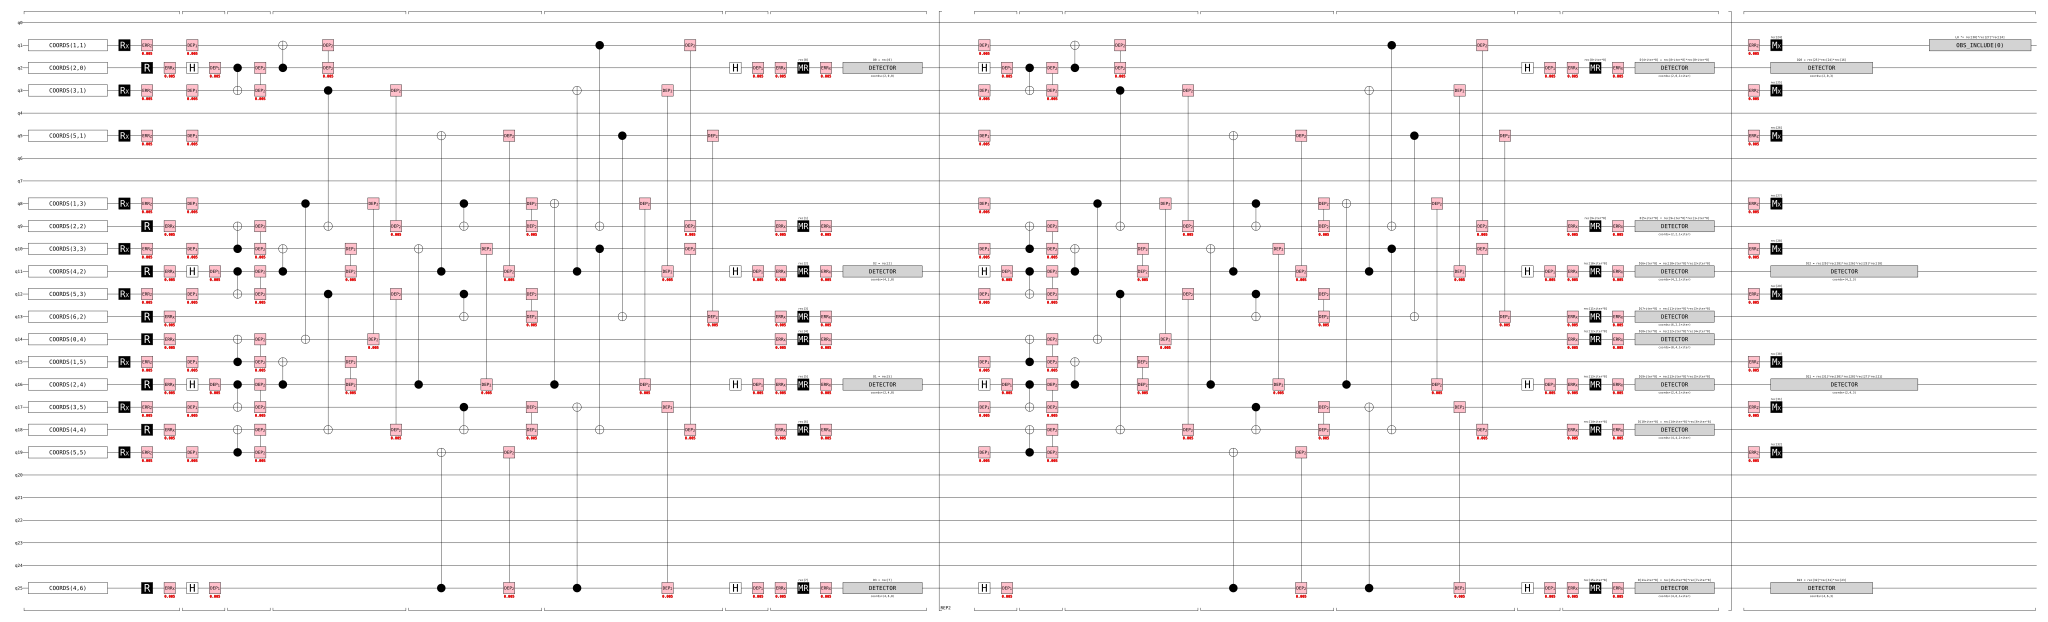

In [11]:
# Display the qubit-coordinate diagram
display(
    surface_x_circuit.diagram(
        "timeline-svg"
    )
)

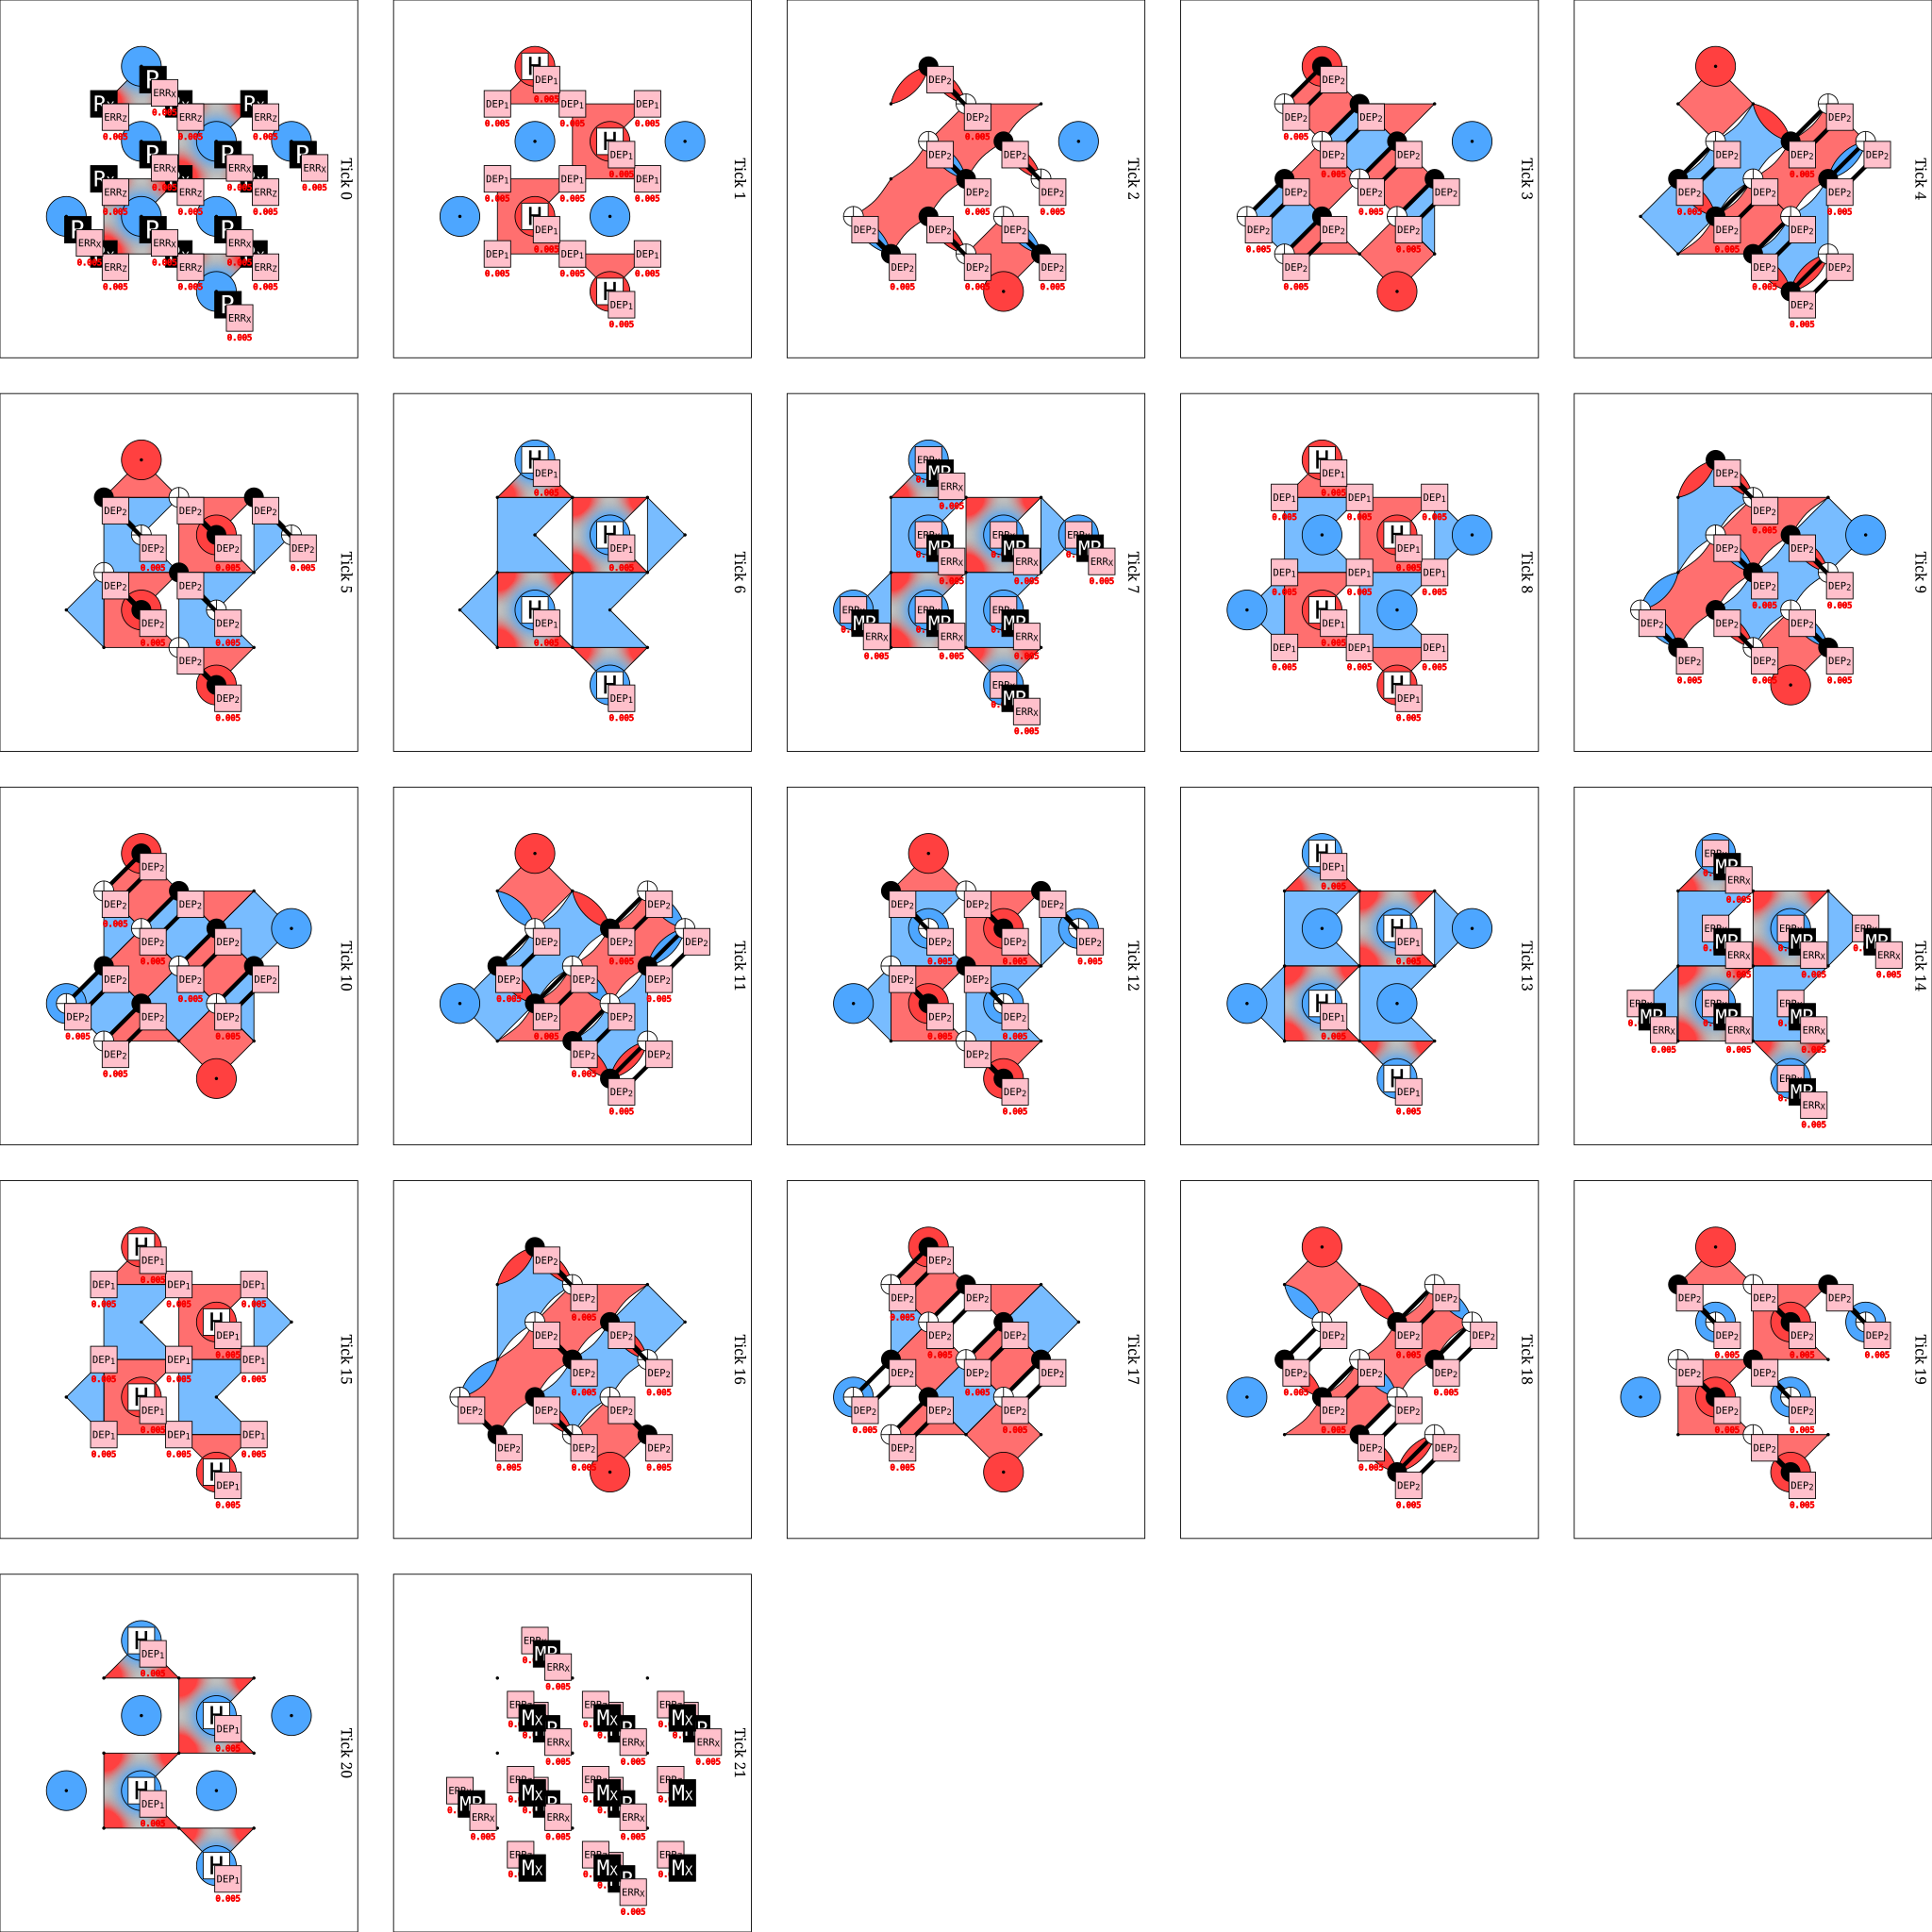

In [12]:
# inspect the detector slice diagram
display(
    surface_x_circuit.diagram(
        "detslice-with-ops-svg"
    )
)

In [13]:
# Save the circuit files
surface_x_path = (
    RESULTS_DIR
    / "surface_code_rotated_memory_x_d3_r3.stim"
)

surface_z_path = (
    RESULTS_DIR
    / "surface_code_rotated_memory_z_d3_r3.stim"
)

surface_x_circuit.to_file(
    surface_x_path
)

surface_z_circuit.to_file(
    surface_z_path
)

print(
    f"Saved logical X circuit to: "
    f"{surface_x_path}"
)

print(
    f"Saved logical Z circuit to: "
    f"{surface_z_path}"
)

Saved logical X circuit to: C:\Users\Karthi\Qauntum\results\surface_code_rotated_memory_x_d3_r3.stim
Saved logical Z circuit to: C:\Users\Karthi\Qauntum\results\surface_code_rotated_memory_z_d3_r3.stim


In [15]:
# Create reusable simulation function
# Generate, sample and decode a rotated surface-code memory experiment
def simulate_surface_code_memory(
    memory_basis,
    distance,
    rounds,
    physical_error_probability,
    number_of_shots,
    seed=SEED,
):


    circuit = (
        create_rotated_surface_code_circuit(
            memory_basis=memory_basis,
            distance=distance,
            rounds=rounds,
            physical_error_probability=(
                physical_error_probability
            ),
        )
    )

    detector_error_model = (
        circuit.detector_error_model(
            decompose_errors=True
        )
    )

    decoder = (
        pymatching.Matching
        .from_detector_error_model(
            detector_error_model
        )
    )

    sampler = (
        circuit.compile_detector_sampler(
            seed=seed
        )
    )

    sampling_start = perf_counter()

    detection_events, actual_observables = (
        sampler.sample(
            shots=number_of_shots,
            separate_observables=True,
        )
    )

    sampling_end = perf_counter()

    # Warm up the decoder before timing.
    decoder.decode_batch(
        detection_events[:1]
    )

    decoding_start = perf_counter()

    predicted_observables = (
        decoder.decode_batch(
            detection_events
        )
    )

    decoding_end = perf_counter()

    decoding_failures = np.any(
        predicted_observables
        != actual_observables,
        axis=1,
    )

    logical_failure_count = int(
        decoding_failures.sum()
    )

    logical_failure_probability = (
        logical_failure_count
        / number_of_shots
    )

    if logical_failure_count > 0:
        standard_error = np.sqrt(
            logical_failure_probability
            * (
                1.0
                - logical_failure_probability
            )
            / number_of_shots
        )
    else:
        standard_error = np.nan

    sampling_time = (
        sampling_end - sampling_start
    )

    decoding_time = (
        decoding_end - decoding_start
    )

    events_per_shot = (
        detection_events.sum(
            axis=1
        )
    )

    return {
        "memory_basis": (
            memory_basis.upper()
        ),
        "distance": distance,
        "rounds": rounds,
        "physical_error_probability": (
            physical_error_probability
        ),
        "shots": number_of_shots,
        "qubits": circuit.num_qubits,
        "measurements": (
            circuit.num_measurements
        ),
        "detectors": (
            circuit.num_detectors
        ),
        "matching_edges": (
            decoder.num_edges
        ),
        "logical_failures": (
            logical_failure_count
        ),
        "logical_failure_probability": (
            logical_failure_probability
        ),
        "standard_error": standard_error,
        "zero_failure_upper_bound_95": (
            3.0 / number_of_shots
            if logical_failure_count == 0
            else np.nan
        ),
        "mean_detection_events": float(
            events_per_shot.mean()
        ),
        "median_detection_events": float(
            np.median(
                events_per_shot
            )
        ),
        "maximum_detection_events": int(
            events_per_shot.max()
        ),
        "sampling_time_seconds": (
            sampling_time
        ),
        "decoding_time_seconds": (
            decoding_time
        ),
        "sampling_throughput": (
            number_of_shots
            / sampling_time
        ),
        "decoding_throughput": (
            number_of_shots
            / decoding_time
        ),
        "decoder_microseconds_per_shot": (
            1e6
            * decoding_time
            / number_of_shots
        ),
        "decoder_microseconds_per_round": (
            1e6
            * decoding_time
            / number_of_shots
            / rounds
        ),
        "detection_events": (
            detection_events
        ),
        "actual_observables": (
            actual_observables
        ),
        "predicted_observables": (
            predicted_observables
        ),
        "decoding_failures_array": (
            decoding_failures
        ),
        "circuit": circuit,
        "detector_error_model": (
            detector_error_model
        ),
    }

In [17]:
number_of_shots = 100_000

In [18]:
# Run the logical X-memory experiment
surface_x_result = (
    simulate_surface_code_memory(
        memory_basis="x",
        distance=distance,
        rounds=rounds,
        physical_error_probability=(
            physical_error_probability
        ),
        number_of_shots=number_of_shots,
        seed=SEED,
    )
)

In [19]:
# Run the logical Z-memory experiment
surface_z_result = (
    simulate_surface_code_memory(
        memory_basis="z",
        distance=distance,
        rounds=rounds,
        physical_error_probability=(
            physical_error_probability
        ),
        number_of_shots=number_of_shots,
        seed=SEED + 1,
    )
)

In [20]:
# Clean summary
# Extract scalar values from a simulation
def create_surface_summary_row(
    result,
):

    excluded_keys = {
        "detection_events",
        "actual_observables",
        "predicted_observables",
        "decoding_failures_array",
        "circuit",
        "detector_error_model",
    }

    return {
        key: value
        for key, value in result.items()
        if key not in excluded_keys
    }

In [21]:
# Table
surface_basis_summary_df = pd.DataFrame(
    [
        create_surface_summary_row(
            surface_x_result
        ),
        create_surface_summary_row(
            surface_z_result
        ),
    ]
)

surface_basis_summary_df[
    [
        "memory_basis",
        "qubits",
        "detectors",
        "matching_edges",
        "logical_failures",
        "logical_failure_probability",
        "mean_detection_events",
        "decoder_microseconds_per_shot",
    ]
]

,memory_basis,qubits,detectors,matching_edges,logical_failures,logical_failure_probability,mean_detection_events,decoder_microseconds_per_shot
0,X,26,24,78,1973,0.01973,1.4613,0.234656
1,Z,26,24,78,1678,0.01678,1.3962,0.220948


In [22]:
# Readable report
for result in [
    surface_x_result,
    surface_z_result,
]:
    print(
        f"Logical {result['memory_basis']} memory"
    )

    print(
        f"  Qubits: "
        f"{result['qubits']}"
    )

    print(
        f"  Detectors: "
        f"{result['detectors']}"
    )

    print(
        f"  Matching edges: "
        f"{result['matching_edges']}"
    )

    print(
        f"  Logical failures: "
        f"{result['logical_failures']:,}"
    )

    print(
        f"  Logical failure probability: "
        f"{result['logical_failure_probability']:.6e}"
    )

    print(
        f"  Mean detection events: "
        f"{result['mean_detection_events']:.4f}"
    )

    print(
        f"  Decoder time: "
        f"{result['decoder_microseconds_per_shot']:.4f} "
        "microseconds/shot"
    )

    print()

Logical X memory
  Qubits: 26
  Detectors: 24
  Matching edges: 78
  Logical failures: 1,973
  Logical failure probability: 1.973000e-02
  Mean detection events: 1.4613
  Decoder time: 0.2347 microseconds/shot

Logical Z memory
  Qubits: 26
  Detectors: 24
  Matching edges: 78
  Logical failures: 1,678
  Logical failure probability: 1.678000e-02
  Mean detection events: 1.3962
  Decoder time: 0.2209 microseconds/shot



In [23]:
# Return an approximate 95% confidence statement
def format_failure_interval(
    result,
):


    probability = result[
        "logical_failure_probability"
    ]

    standard_error = result[
        "standard_error"
    ]

    if result["logical_failures"] == 0:
        return {
            "lower": 0.0,
            "upper": result[
                "zero_failure_upper_bound_95"
            ],
            "method": "rule_of_three",
        }

    return {
        "lower": max(
            0.0,
            probability
            - 1.96 * standard_error,
        ),
        "upper": min(
            1.0,
            probability
            + 1.96 * standard_error,
        ),
        "method": "normal_approximation",
    }

In [24]:
# Apply
for result in [
    surface_x_result,
    surface_z_result,
]:
    interval = format_failure_interval(
        result
    )

    print(
        f"Logical {result['memory_basis']} "
        f"95% interval or bound: "
        f"[{interval['lower']:.6e}, "
        f"{interval['upper']:.6e}] "
        f"using {interval['method']}"
    )

Logical X 95% interval or bound: [1.886803e-02, 2.059197e-02] using normal_approximation
Logical Z 95% interval or bound: [1.598388e-02, 1.757612e-02] using normal_approximation


In [25]:
# Compare the measured failure rates between logical X and Z
x_probability = surface_x_result[
    "logical_failure_probability"
]

z_probability = surface_z_result[
    "logical_failure_probability"
]

absolute_basis_difference = abs(
    x_probability - z_probability
)

print(
    f"Absolute X/Z failure-rate difference: "
    f"{absolute_basis_difference:.6e}"
)

Absolute X/Z failure-rate difference: 2.950000e-03


In [26]:
# Estimate the uncertainty in the difference when both experiments observed failures
if (
    surface_x_result["logical_failures"] > 0
    and surface_z_result["logical_failures"] > 0
):
    difference_standard_error = np.sqrt(
        surface_x_result[
            "standard_error"
        ] ** 2
        + surface_z_result[
            "standard_error"
        ] ** 2
    )

    difference_in_standard_errors = (
        absolute_basis_difference
        / difference_standard_error
    )

    print(
        "Difference in combined standard errors: "
        f"{difference_in_standard_errors:.2f}"
    )

Difference in combined standard errors: 4.93


In [27]:
# Compare event counts
x_events_per_shot = (
    surface_x_result[
        "detection_events"
    ].sum(
        axis=1
    )
)

z_events_per_shot = (
    surface_z_result[
        "detection_events"
    ].sum(
        axis=1
    )
)

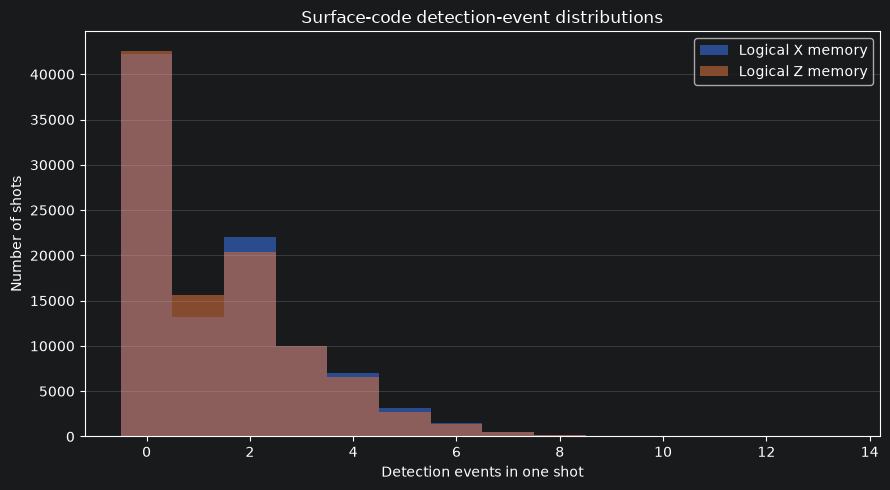

Saved figure to: C:\Users\Karthi\Qauntum\figures\surface_code_basis_event_distributions.png


In [28]:
# Plot
combined_maximum = int(
    max(
        x_events_per_shot.max(),
        z_events_per_shot.max(),
    )
)

maximum_events_to_plot = min(
    combined_maximum,
    30,
)

event_bins = np.arange(
    -0.5,
    maximum_events_to_plot + 1.5,
    1.0,
)

figure, axis = plt.subplots(
    figsize=(9, 5)
)

axis.hist(
    x_events_per_shot[
        x_events_per_shot
        <= maximum_events_to_plot
    ],
    bins=event_bins,
    alpha=0.6,
    label="Logical X memory",
)

axis.hist(
    z_events_per_shot[
        z_events_per_shot
        <= maximum_events_to_plot
    ],
    bins=event_bins,
    alpha=0.6,
    label="Logical Z memory",
)

axis.set_xlabel(
    "Detection events in one shot"
)

axis.set_ylabel(
    "Number of shots"
)

axis.set_title(
    "Surface-code detection-event distributions"
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

surface_event_distribution_path = (
    FIGURE_DIR
    / "surface_code_basis_event_distributions.png"
)

figure.savefig(
    surface_event_distribution_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{surface_event_distribution_path}"
)

In [29]:
# Compare event counts in successful and failed shots
# Examine event density at logical failure
def summarise_events_by_outcome(
    result,
):

    events_per_shot = result[
        "detection_events"
    ].sum(
        axis=1
    )

    failures = result[
        "decoding_failures_array"
    ]

    successful_events = events_per_shot[
        ~failures
    ]

    failed_events = events_per_shot[
        failures
    ]

    summary = {
        "memory_basis": result[
            "memory_basis"
        ],
        "successful_shots": int(
            (~failures).sum()
        ),
        "failed_shots": int(
            failures.sum()
        ),
        "successful_mean_events": float(
            successful_events.mean()
        ),
        "failed_mean_events": (
            float(
                failed_events.mean()
            )
            if len(failed_events) > 0
            else np.nan
        ),
        "successful_median_events": float(
            np.median(
                successful_events
            )
        ),
        "failed_median_events": (
            float(
                np.median(
                    failed_events
                )
            )
            if len(failed_events) > 0
            else np.nan
        ),
    }

    return summary

In [30]:
# Summary
surface_outcome_summary_df = pd.DataFrame(
    [
        summarise_events_by_outcome(
            surface_x_result
        ),
        summarise_events_by_outcome(
            surface_z_result
        ),
    ]
)

surface_outcome_summary_df

,memory_basis,successful_shots,failed_shots,successful_mean_events,failed_mean_events,successful_median_events,failed_median_events
0,X,98027,1973,1.409448,4.037506,1.0,4.0
1,Z,98322,1678,1.352688,3.945769,1.0,4.0


In [31]:
# Compare distances 3, 5 and 7
surface_distances = [
    3,
    5,
    7,
]

surface_scaling_shots = 100_000
surface_scaling_probability = 0.005

In [32]:
# Run bases
surface_scaling_results = []

configuration_index = 0

for memory_basis in [
    "x",
    "z",
]:
    for surface_distance in (
        surface_distances
    ):
        configuration_index += 1

        print(
            f"Running basis={memory_basis.upper()} | "
            f"distance={surface_distance}"
        )

        result = (
            simulate_surface_code_memory(
                memory_basis=memory_basis,
                distance=surface_distance,
                rounds=surface_distance,
                physical_error_probability=(
                    surface_scaling_probability
                ),
                number_of_shots=(
                    surface_scaling_shots
                ),
                seed=(
                    SEED
                    + 100
                    + configuration_index
                ),
            )
        )

        surface_scaling_results.append(
            create_surface_summary_row(
                result
            )
        )

        print(
            f"  failures="
            f"{result['logical_failures']:,} | "
            f"logical="
            f"{result['logical_failure_probability']:.6e} | "
            f"decode="
            f"{result['decoder_microseconds_per_round']:.4f} "
            "us/round"
        )

Running basis=X | distance=3
  failures=1,910 | logical=1.910000e-02 | decode=0.0801 us/round
Running basis=X | distance=5
  failures=1,656 | logical=1.656000e-02 | decode=0.3737 us/round
Running basis=X | distance=7
  failures=1,246 | logical=1.246000e-02 | decode=0.8964 us/round
Running basis=Z | distance=3
  failures=1,774 | logical=1.774000e-02 | decode=0.0732 us/round
Running basis=Z | distance=5
  failures=1,440 | logical=1.440000e-02 | decode=0.3602 us/round
Running basis=Z | distance=7
  failures=1,027 | logical=1.027000e-02 | decode=0.8739 us/round


In [33]:
# Table Conversion
surface_scaling_df = pd.DataFrame(
    surface_scaling_results
)

surface_scaling_df[
    [
        "memory_basis",
        "distance",
        "qubits",
        "detectors",
        "logical_failures",
        "logical_failure_probability",
        "decoder_microseconds_per_round",
    ]
]

,memory_basis,distance,qubits,detectors,logical_failures,logical_failure_probability,decoder_microseconds_per_round
0,X,3,26,24,1910,0.01910,0.080090
1,X,5,64,120,1656,0.01656,0.373740
2,X,7,118,336,1246,0.01246,0.896414
3,Z,3,26,24,1774,0.01774,0.073188
4,Z,5,64,120,1440,0.01440,0.360182
5,Z,7,118,336,1027,0.01027,0.873927


In [34]:
# Upper-bound plotting values
surface_scaling_df[
    "logical_probability_for_plot"
] = np.where(
    surface_scaling_df[
        "logical_failures"
    ] > 0,
    surface_scaling_df[
        "logical_failure_probability"
    ],
    surface_scaling_df[
        "zero_failure_upper_bound_95"
    ],
)

surface_scaling_df[
    "used_upper_bound"
] = (
    surface_scaling_df[
        "logical_failures"
    ] == 0
)

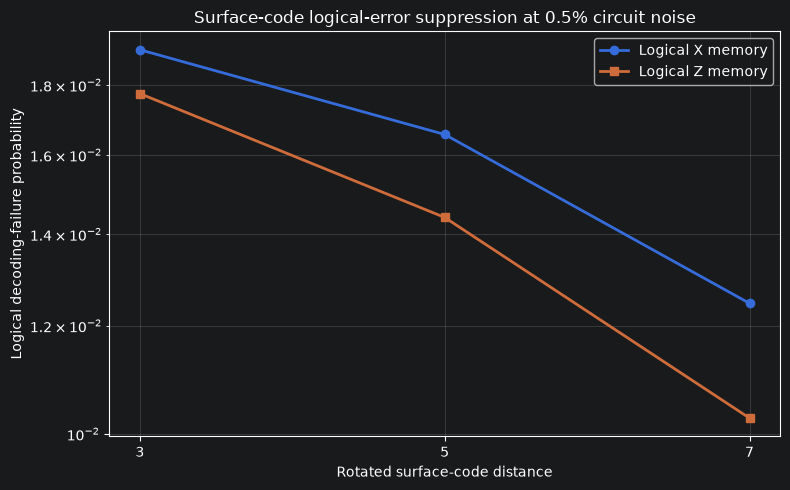

Saved figure to: C:\Users\Karthi\Qauntum\figures\surface_code_distance_scaling.png


In [35]:
# Plot logical failure against distance
figure, axis = plt.subplots(
    figsize=(8, 5)
)

for memory_basis, marker in [
    ("X", "o"),
    ("Z", "s"),
]:
    subset = surface_scaling_df[
        surface_scaling_df[
            "memory_basis"
        ] == memory_basis
    ].sort_values(
        "distance"
    )

    axis.plot(
        subset["distance"],
        subset[
            "logical_probability_for_plot"
        ],
        marker=marker,
        linewidth=2,
        label=(
            f"Logical {memory_basis} memory"
        ),
    )

axis.set_yscale("log")

axis.set_xlabel(
    "Rotated surface-code distance"
)

axis.set_ylabel(
    "Logical decoding-failure probability"
)

axis.set_title(
    "Surface-code logical-error suppression "
    "at 0.5% circuit noise"
)

axis.set_xticks(
    surface_distances
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

surface_distance_path = (
    FIGURE_DIR
    / "surface_code_distance_scaling.png"
)

figure.savefig(
    surface_distance_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{surface_distance_path}"
)

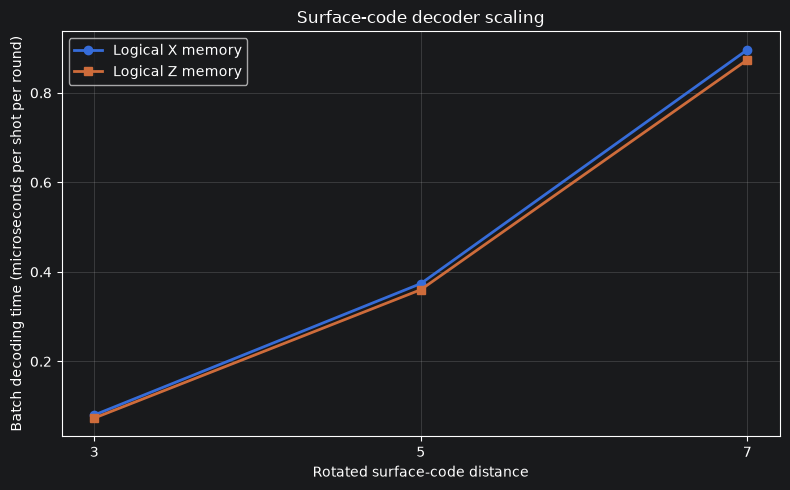

Saved figure to: C:\Users\Karthi\Qauntum\figures\surface_code_decoder_scaling.png


In [36]:
# Plot decoder time per round
figure, axis = plt.subplots(
    figsize=(8, 5)
)

for memory_basis, marker in [
    ("X", "o"),
    ("Z", "s"),
]:
    subset = surface_scaling_df[
        surface_scaling_df[
            "memory_basis"
        ] == memory_basis
    ].sort_values(
        "distance"
    )

    axis.plot(
        subset["distance"],
        subset[
            "decoder_microseconds_per_round"
        ],
        marker=marker,
        linewidth=2,
        label=(
            f"Logical {memory_basis} memory"
        ),
    )

axis.set_xlabel(
    "Rotated surface-code distance"
)

axis.set_ylabel(
    "Batch decoding time "
    "(microseconds per shot per round)"
)

axis.set_title(
    "Surface-code decoder scaling"
)

axis.set_xticks(
    surface_distances
)

axis.grid(
    True,
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

surface_decoder_path = (
    FIGURE_DIR
    / "surface_code_decoder_scaling.png"
)

figure.savefig(
    surface_decoder_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{surface_decoder_path}"
)

In [37]:
# Export the results
surface_properties_path = (
    RESULTS_DIR
    / "surface_code_circuit_properties.csv"
)

surface_circuit_properties.to_csv(
    surface_properties_path,
    index=False,
)

surface_basis_summary_path = (
    RESULTS_DIR
    / "surface_code_basis_summary.csv"
)

surface_basis_summary_df.to_csv(
    surface_basis_summary_path,
    index=False,
)

surface_outcome_summary_path = (
    RESULTS_DIR
    / "surface_code_outcome_event_summary.csv"
)

surface_outcome_summary_df.to_csv(
    surface_outcome_summary_path,
    index=False,
)

surface_scaling_results_path = (
    RESULTS_DIR
    / "surface_code_distance_scaling.csv"
)

surface_scaling_df.to_csv(
    surface_scaling_results_path,
    index=False,
)

print(
    f"Saved basis summary to: "
    f"{surface_basis_summary_path}"
)

print(
    f"Saved distance scaling to: "
    f"{surface_scaling_results_path}"
)

Saved basis summary to: C:\Users\Karthi\Qauntum\results\surface_code_basis_summary.csv
Saved distance scaling to: C:\Users\Karthi\Qauntum\results\surface_code_distance_scaling.csv


# Surface-Code Results

The rotated surface-code circuits protected a single logical observable using repeated stabilizer measurements across a two-dimensional qubit lattice.

### Basis Symmetry and Decoding
* **Logical $X$- vs. $Z$-Memory:** The $X$-memory experiment prepared and measured the logical qubit in the $X$ basis, whereas the $Z$-memory experiment operated in the $Z$ basis. Under a symmetric depolarising noise model, both bases exhibit broadly comparable logical failure probabilities, with minor variations attributable to finite-shot sampling noise.
* **Graph-Based Decoding:** The detector error model (DEM) mapped circuit-level faults to detection-event patterns and logical-observable flips. PyMatching then identified a minimum-weight set of graph-like faults consistent with each observed syndrome sample.

### Distance Scaling and Error Topology
* **Distance vs. Overhead:** Increasing the code distance $d$ expanded the number of physical qubits, detectors, and matching-graph edges. While this increased the classical decoding workload, it delivered stronger logical-error suppression when operating below the code's threshold region.
* **Syndrome Topology:** Shots resulting in logical decoding failures tended to exhibit higher average detection-event counts, though event count alone does not identify hard instances. Rather, the spatial and temporal arrangement of detection events determines whether competing matching solutions differ by a non-trivial logical operator.

### Experimental and Architectural Caveats
* **Throughput vs. Real-Time Latency:** The reported batch-decoding time reflects aggregate CPU throughput rather than compliance with a real-time syndrome-cycle deadline. Evaluating real-time viability requires accounting for single-shot latency, syndrome backlog accumulation, data-transfer delays, and streaming overhead from the quantum-control hardware to the classical decoder.
* **Noise Model Limitations:** The current model assigns a uniform error probability across distinct physical processes. A hardware-realistic model should incorporate experimentally calibrated gate, reset, idle, and readout error rates, alongside non-Pauli effects such as leakage, crosstalk, and correlated faults.
